In [1]:

# Download the Facades dataset
!wget -q https://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz

# Extract the dataset
!tar -xzf facades.tar.gz

# Check dataset folders
import os

print("Dataset downloaded successfully!")

for folder in ["facades/train", "facades/val", "facades/test"]:
    if os.path.exists(folder):
        print(f"{folder}: {len(os.listdir(folder))} images")
    else:
        print(f"{folder}: Not found")


Dataset downloaded successfully!
facades/train: 400 images
facades/val: 100 images
facades/test: 106 images


Image dimensions: (512, 256)
Image mode: RGB


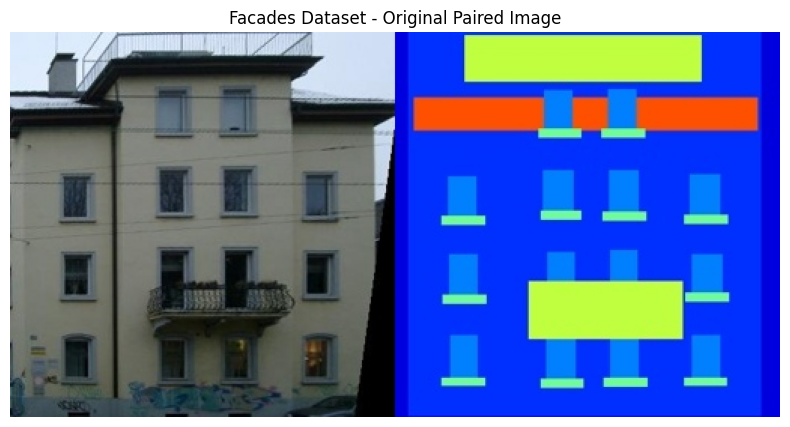

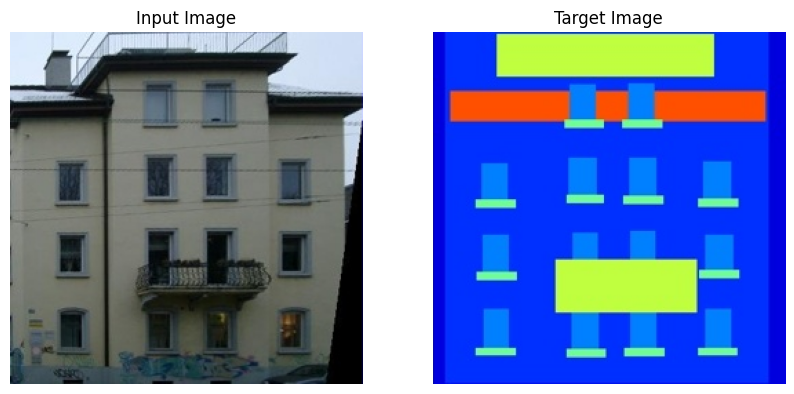

In [2]:

import os
from PIL import Image
import matplotlib.pyplot as plt

# Load one training image
image_path = "facades/train/" + os.listdir("facades/train")[0]
image = Image.open(image_path)

print("Image dimensions:", image.size)
print("Image mode:", image.mode)

# Display original paired image
plt.figure(figsize=(12, 5))
plt.imshow(image)
plt.title("Facades Dataset - Original Paired Image")
plt.axis("off")
plt.show()

# Split into input and target
width, height = image.size
input_image = image.crop((0, 0, width // 2, height))
target_image = image.crop((width // 2, 0, width, height))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(input_image)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(target_image)
axes[1].set_title("Target Image")
axes[1].axis("off")

plt.show()


Input tensor shape: torch.Size([3, 256, 256])
Target tensor shape: torch.Size([3, 256, 256])


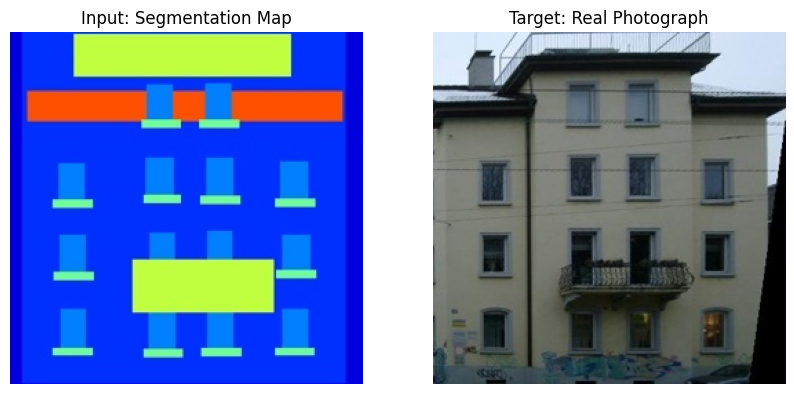

In [3]:

import torch
from PIL import Image
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import os

IMAGE_SIZE = 256

# Convert paired image into input and target
def load_paired_image(image_path):
    image = Image.open(image_path).convert("RGB")

    width, height = image.size

    # Right half = input segmentation map
    input_image = image.crop(
        (width // 2, 0, width, height)
    )

    # Left half = target real photograph
    target_image = image.crop(
        (0, 0, width // 2, height)
    )

    return input_image, target_image


# Transform images into PyTorch tensors
transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=transforms.InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])


# Test preprocessing
sample_file = os.listdir("facades/train")[0]
sample_path = os.path.join("facades/train", sample_file)

input_image, target_image = load_paired_image(sample_path)

input_tensor = transform(input_image)
target_tensor = transform(target_image)

print("Input tensor shape:", input_tensor.shape)
print("Target tensor shape:", target_tensor.shape)

# Display processed images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(input_image)
axes[0].set_title("Input: Segmentation Map")
axes[0].axis("off")

axes[1].imshow(target_image)
axes[1].set_title("Target: Real Photograph")
axes[1].axis("off")

plt.show()


In [4]:

import torch
import torch.nn as nn


# Encoder block
def down_block(in_channels, out_channels, normalize=True):
    layers = [
        nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1,
            bias=not normalize
        )
    ]

    if normalize:
        layers.append(nn.BatchNorm2d(out_channels))

    layers.append(nn.LeakyReLU(0.2, inplace=True))

    return nn.Sequential(*layers)


# Decoder block
def up_block(in_channels, out_channels, dropout=False):
    layers = [
        nn.ConvTranspose2d(
            in_channels,
            out_channels,
            kernel_size=4,
            stride=2,
            padding=1,
            bias=False
        ),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    ]

    if dropout:
        layers.append(nn.Dropout(0.5))

    return nn.Sequential(*layers)


# U-Net Generator
class Generator(nn.Module):

    def __init__(self, in_channels=3, out_channels=3):
        super(Generator, self).__init__()

        # Encoder
        self.down1 = down_block(in_channels, 64, normalize=False)
        self.down2 = down_block(64, 128)
        self.down3 = down_block(128, 256)
        self.down4 = down_block(256, 512)
        self.down5 = down_block(512, 512)
        self.down6 = down_block(512, 512)
        self.down7 = down_block(512, 512)
        self.down8 = down_block(512, 512, normalize=False)

        # Decoder
        self.up1 = up_block(512, 512, dropout=True)
        self.up2 = up_block(1024, 512, dropout=True)
        self.up3 = up_block(1024, 512, dropout=True)
        self.up4 = up_block(1024, 512)
        self.up5 = up_block(1024, 256)
        self.up6 = up_block(512, 128)
        self.up7 = up_block(256, 64)

        # Final output
        self.final = nn.Sequential(
            nn.ConvTranspose2d(
                128,
                out_channels,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.Tanh()
        )

    def forward(self, x):

        # Encoder
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        # Decoder with skip connections
        u1 = self.up1(d8)
        u1 = torch.cat([u1, d7], dim=1)

        u2 = self.up2(u1)
        u2 = torch.cat([u2, d6], dim=1)

        u3 = self.up3(u2)
        u3 = torch.cat([u3, d5], dim=1)

        u4 = self.up4(u3)
        u4 = torch.cat([u4, d4], dim=1)

        u5 = self.up5(u4)
        u5 = torch.cat([u5, d3], dim=1)

        u6 = self.up6(u5)
        u6 = torch.cat([u6, d2], dim=1)

        u7 = self.up7(u6)
        u7 = torch.cat([u7, d1], dim=1)

        return self.final(u7)


# Initialize generator
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

generator = Generator().to(device)

# Test generator
test_input = torch.randn(2, 3, 256, 256).to(device)

with torch.no_grad():
    test_output = generator(test_input)

print("Generator initialized successfully!")
print("Device:", device)
print("Input shape:", test_input.shape)
print("Output shape:", test_output.shape)
print(
    "Total parameters:",
    sum(p.numel() for p in generator.parameters())
)


Generator initialized successfully!
Device: cuda
Input shape: torch.Size([2, 3, 256, 256])
Output shape: torch.Size([2, 3, 256, 256])
Total parameters: 54414531


In [5]:

import torch
import torch.nn as nn


class Discriminator(nn.Module):

    def __init__(self, in_channels=6):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(

            # Layer 1
            nn.Conv2d(
                in_channels, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 2
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 3
            nn.Conv2d(
                128, 256,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 4
            nn.Conv2d(
                256, 512,
                kernel_size=4,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            # Output layer
            nn.Conv2d(
                512, 1,
                kernel_size=4,
                stride=1,
                padding=1
            )
        )

    def forward(self, input_image, target_image):

        # Combine condition and target images
        combined = torch.cat(
            (input_image, target_image),
            dim=1
        )

        return self.model(combined)


# Initialize discriminator
discriminator = Discriminator().to(device)

# Test discriminator
test_input = torch.randn(2, 3, 256, 256).to(device)
test_target = torch.randn(2, 3, 256, 256).to(device)

with torch.no_grad():
    test_output = discriminator(test_input, test_target)

print("Discriminator initialized successfully!")
print("Device:", device)
print("Input image shape:", test_input.shape)
print("Target image shape:", test_target.shape)
print("Discriminator output shape:", test_output.shape)
print(
    "Total parameters:",
    sum(p.numel() for p in discriminator.parameters())
)


Discriminator initialized successfully!
Device: cuda
Input image shape: torch.Size([2, 3, 256, 256])
Target image shape: torch.Size([2, 3, 256, 256])
Discriminator output shape: torch.Size([2, 1, 30, 30])
Total parameters: 2768705


In [6]:

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import os

class FacadesDataset(Dataset):

    def __init__(self, root_dir, split):
        self.image_dir = os.path.join(root_dir, split)

        self.image_files = sorted([
            f for f in os.listdir(self.image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):

        image_path = os.path.join(
            self.image_dir,
            self.image_files[index]
        )

        input_image, target_image = load_paired_image(image_path)

        input_tensor = transform(input_image)
        target_tensor = transform(target_image)

        return input_tensor, target_tensor


# Create datasets
train_dataset = FacadesDataset("facades", "train")
val_dataset = FacadesDataset("facades", "val")
test_dataset = FacadesDataset("facades", "test")

# Create DataLoaders
BATCH_SIZE = 1

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Verify datasets and batches
print("Dataset preparation completed!")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

sample_input, sample_target = next(iter(train_loader))

print("\nBatch verification:")
print("Input shape:", sample_input.shape)
print("Target shape:", sample_target.shape)
print("Batch size:", BATCH_SIZE)
print("Device:", device)


Dataset preparation completed!
Training images: 400
Validation images: 100
Testing images: 106

Batch verification:
Input shape: torch.Size([1, 3, 256, 256])
Target shape: torch.Size([1, 3, 256, 256])
Batch size: 1
Device: cuda


In [7]:

import torch
import torch.nn as nn
import torch.optim as optim


# Initialize model weights
def initialize_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)

        if module.bias is not None:
            nn.init.zeros_(module.bias)

    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


# Apply initialization
generator.apply(initialize_weights)
discriminator.apply(initialize_weights)


# Loss functions
adversarial_loss = nn.BCEWithLogitsLoss()
pixel_loss = nn.L1Loss()

LAMBDA_L1 = 100


# Optimizers
LEARNING_RATE = 0.0002

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999)
)


# Training configuration
EPOCHS = 100

print("Pix2Pix training configuration completed!")
print("Generator parameters:", sum(
    p.numel() for p in generator.parameters()
))
print("Discriminator parameters:", sum(
    p.numel() for p in discriminator.parameters()
))
print("Learning rate:", LEARNING_RATE)
print("L1 loss weight:", LAMBDA_L1)
print("Epochs:", EPOCHS)
print("Device:", device)


Pix2Pix training configuration completed!
Generator parameters: 54414531
Discriminator parameters: 2768705
Learning rate: 0.0002
L1 loss weight: 100
Epochs: 100
Device: cuda


In [8]:

import os
import torch
from tqdm.auto import tqdm
from torchvision.utils import save_image

# Create folders for checkpoints and generated samples
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("generated_samples", exist_ok=True)

# Initial training stage
EPOCHS_TO_RUN = 10
best_val_l1 = float("inf")

# Save a fixed validation example for visual comparison
sample_input, sample_target = val_dataset[0]
sample_input = sample_input.unsqueeze(0).to(device)

print("Starting Pix2Pix training...")
print("Training epochs:", EPOCHS_TO_RUN)

for epoch in range(1, EPOCHS_TO_RUN + 1):

    generator.train()
    discriminator.train()

    total_G_loss = 0.0
    total_D_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS_TO_RUN}"
    )

    for real_input, real_target in progress_bar:

        real_input = real_input.to(device)
        real_target = real_target.to(device)

        # -------------------------
        # Train Discriminator
        # -------------------------

        optimizer_D.zero_grad()

        fake_target = generator(real_input)

        real_prediction = discriminator(
            real_input, real_target
        )

        fake_prediction = discriminator(
            real_input, fake_target.detach()
        )

        real_labels = torch.ones_like(real_prediction)
        fake_labels = torch.zeros_like(fake_prediction)

        loss_D_real = adversarial_loss(
            real_prediction, real_labels
        )

        loss_D_fake = adversarial_loss(
            fake_prediction, fake_labels
        )

        loss_D = (loss_D_real + loss_D_fake) * 0.5

        loss_D.backward()
        optimizer_D.step()

        # -------------------------
        # Train Generator
        # -------------------------

        optimizer_G.zero_grad()

        fake_prediction = discriminator(
            real_input, fake_target
        )

        loss_G_GAN = adversarial_loss(
            fake_prediction,
            torch.ones_like(fake_prediction)
        )

        loss_G_L1 = pixel_loss(
            fake_target, real_target
        )

        loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1

        loss_G.backward()
        optimizer_G.step()

        total_G_loss += loss_G.item()
        total_D_loss += loss_D.item()

        progress_bar.set_postfix({
            "G Loss": f"{loss_G.item():.3f}",
            "D Loss": f"{loss_D.item():.3f}"
        })

    # Average training losses
    avg_G_loss = total_G_loss / len(train_loader)
    avg_D_loss = total_D_loss / len(train_loader)

    # -------------------------
    # Validation
    # -------------------------

    generator.eval()
    val_l1_total = 0.0

    with torch.no_grad():

        for val_input, val_target in val_loader:

            val_input = val_input.to(device)
            val_target = val_target.to(device)

            generated = generator(val_input)

            val_l1_total += pixel_loss(
                generated, val_target
            ).item()

    avg_val_l1 = val_l1_total / len(val_loader)

    print(
        f"\nEpoch {epoch}/{EPOCHS_TO_RUN} | "
        f"G Loss: {avg_G_loss:.4f} | "
        f"D Loss: {avg_D_loss:.4f} | "
        f"Validation L1: {avg_val_l1:.4f}"
    )

    # -------------------------
    # Save latest checkpoint
    # -------------------------

    checkpoint = {
        "epoch": epoch,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "best_val_l1": min(best_val_l1, avg_val_l1)
    }

    torch.save(
        checkpoint,
        "checkpoints/latest_checkpoint.pth"
    )

    # Save best generator
    if avg_val_l1 < best_val_l1:

        best_val_l1 = avg_val_l1

        torch.save(
            generator.state_dict(),
            "checkpoints/best_generator.pth"
        )

        print("New best generator saved!")

    # Save sample images every 5 epochs
    if epoch % 5 == 0:

        with torch.no_grad():
            generated_sample = generator(sample_input)

        save_image(
            (sample_input.cpu() + 1) / 2,
            f"generated_samples/input_epoch_{epoch}.png"
        )

        save_image(
            (generated_sample.cpu() + 1) / 2,
            f"generated_samples/generated_epoch_{epoch}.png"
        )

        save_image(
            (sample_target.unsqueeze(0) + 1) / 2,
            f"generated_samples/target_epoch_{epoch}.png"
        )

        print("Sample images saved!")

print("\nInitial training stage completed!")
print("Latest checkpoint: checkpoints/latest_checkpoint.pth")
print("Best generator: checkpoints/best_generator.pth")


Starting Pix2Pix training...
Training epochs: 10


Epoch 1/10:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 1/10 | G Loss: 39.6231 | D Loss: 0.3102 | Validation L1: 0.3685
New best generator saved!


Epoch 2/10:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 2/10 | G Loss: 40.1922 | D Loss: 0.2685 | Validation L1: 0.3738


Epoch 3/10:   0%|          | 0/400 [00:00<?, ?it/s]

... (14 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7993fef6cd60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7993fef6cd60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 9/10 | G Loss: 37.0554 | D Loss: 0.3283 | Validation L1: 0.3767


Epoch 10/10:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 10/10 | G Loss: 35.9430 | D Loss: 0.3510 | Validation L1: 0.3940
Sample images saved!

Initial training stage completed!
Latest checkpoint: checkpoints/latest_checkpoint.pth
Best generator: checkpoints/best_generator.pth


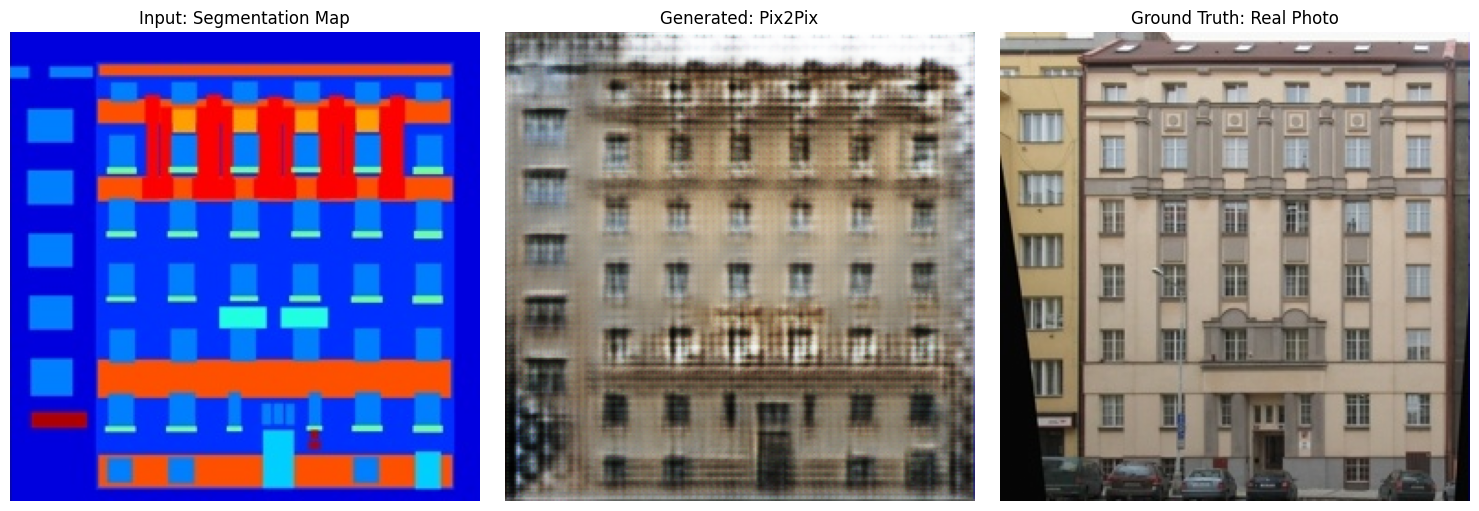

In [9]:

import torch
import matplotlib.pyplot as plt

# Load best generator checkpoint
generator.load_state_dict(
    torch.load(
        "checkpoints/best_generator.pth",
        map_location=device,
        weights_only=True
    )
)

generator.eval()

# Select a test image
test_input, test_target = test_dataset[0]

test_input = test_input.unsqueeze(0).to(device)

# Generate image
with torch.no_grad():
    generated_image = generator(test_input)

# Convert tensors from [-1, 1] to [0, 1]
def denormalize(tensor):
    return (tensor.clamp(-1, 1) + 1) / 2

input_display = denormalize(test_input.cpu())[0]
generated_display = denormalize(generated_image.cpu())[0]
target_display = denormalize(test_target.unsqueeze(0))[0]

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    input_display,
    generated_display,
    target_display
]

titles = [
    "Input: Segmentation Map",
    "Generated: Pix2Pix",
    "Ground Truth: Real Photo"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:

import torch
from tqdm.auto import tqdm
from torchvision.utils import save_image

# Restore the latest checkpoint (epoch 10)
checkpoint = torch.load(
    "checkpoints/latest_checkpoint.pth",
    map_location=device,
    weights_only=False
)

generator.load_state_dict(checkpoint["generator"])
discriminator.load_state_dict(checkpoint["discriminator"])

optimizer_G.load_state_dict(checkpoint["optimizer_G"])
optimizer_D.load_state_dict(checkpoint["optimizer_D"])

start_epoch = checkpoint["epoch"] + 1
best_val_l1 = checkpoint["best_val_l1"]

END_EPOCH = 20

print(f"Resuming from epoch {start_epoch}...")
print(f"Best validation L1 so far: {best_val_l1:.4f}")

for epoch in range(start_epoch, END_EPOCH + 1):

    generator.train()
    discriminator.train()

    total_G_loss = 0.0
    total_D_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{END_EPOCH}"
    )

    for real_input, real_target in progress_bar:

        real_input = real_input.to(device)
        real_target = real_target.to(device)

        # Train Discriminator
        optimizer_D.zero_grad()

        fake_target = generator(real_input)

        real_prediction = discriminator(
            real_input, real_target
        )

        fake_prediction = discriminator(
            real_input, fake_target.detach()
        )

        loss_D_real = adversarial_loss(
            real_prediction,
            torch.ones_like(real_prediction)
        )

        loss_D_fake = adversarial_loss(
            fake_prediction,
            torch.zeros_like(fake_prediction)
        )

        loss_D = (loss_D_real + loss_D_fake) * 0.5

        loss_D.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()

        fake_prediction = discriminator(
            real_input, fake_target
        )

        loss_G_GAN = adversarial_loss(
            fake_prediction,
            torch.ones_like(fake_prediction)
        )

        loss_G_L1 = pixel_loss(fake_target, real_target)

        loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1

        loss_G.backward()
        optimizer_G.step()

        total_G_loss += loss_G.item()
        total_D_loss += loss_D.item()

        progress_bar.set_postfix({
            "G": f"{loss_G.item():.3f}",
            "D": f"{loss_D.item():.3f}"
        })

    avg_G_loss = total_G_loss / len(train_loader)
    avg_D_loss = total_D_loss / len(train_loader)

    # Validation
    generator.eval()
    val_l1_total = 0.0

    with torch.no_grad():
        for val_input, val_target in val_loader:
            val_input = val_input.to(device)
            val_target = val_target.to(device)

            generated = generator(val_input)
            val_l1_total += pixel_loss(
                generated, val_target
            ).item()

    avg_val_l1 = val_l1_total / len(val_loader)

    print(
        f"\nEpoch {epoch} | "
        f"G Loss: {avg_G_loss:.4f} | "
        f"D Loss: {avg_D_loss:.4f} | "
        f"Validation L1: {avg_val_l1:.4f}"
    )

    # Save latest checkpoint
    torch.save({
        "epoch": epoch,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "best_val_l1": min(best_val_l1, avg_val_l1)
    }, "checkpoints/latest_checkpoint.pth")

    # Save best generator
    if avg_val_l1 < best_val_l1:
        best_val_l1 = avg_val_l1

        torch.save(
            generator.state_dict(),
            "checkpoints/best_generator.pth"
        )

        print("New best generator saved!")

    # Save generated samples
    if epoch % 5 == 0:
        sample_input, sample_target = val_dataset[0]
        sample_input = sample_input.unsqueeze(0).to(device)

        with torch.no_grad():
            generated_sample = generator(sample_input)

        save_image(
            (generated_sample.cpu() + 1) / 2,
            f"generated_samples/generated_epoch_{epoch}.png"
        )

        print("Generated sample saved!")

print("\nTraining stage completed!")
print("Latest epoch:", END_EPOCH)
print("Best validation L1:", best_val_l1)


Resuming from epoch 11...
Best validation L1 so far: 0.3667


Epoch 11/20:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 11 | G Loss: 35.0452 | D Loss: 0.3490 | Validation L1: 0.3732


Epoch 12/20:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 12 | G Loss: 33.9895 | D Loss: 0.3525 | Validation L1: 0.3761


Epoch 13/20:   0%|          | 0/400 [00:00<?, ?it/s]

... (13 outputs left out)

Epoch 19/20:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 19 | G Loss: 27.7986 | D Loss: 0.3757 | Validation L1: 0.3851


Epoch 20/20:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 20 | G Loss: 27.1987 | D Loss: 0.3759 | Validation L1: 0.3658
New best generator saved!
Generated sample saved!

Training stage completed!
Latest epoch: 20
Best validation L1: 0.36579188421368597


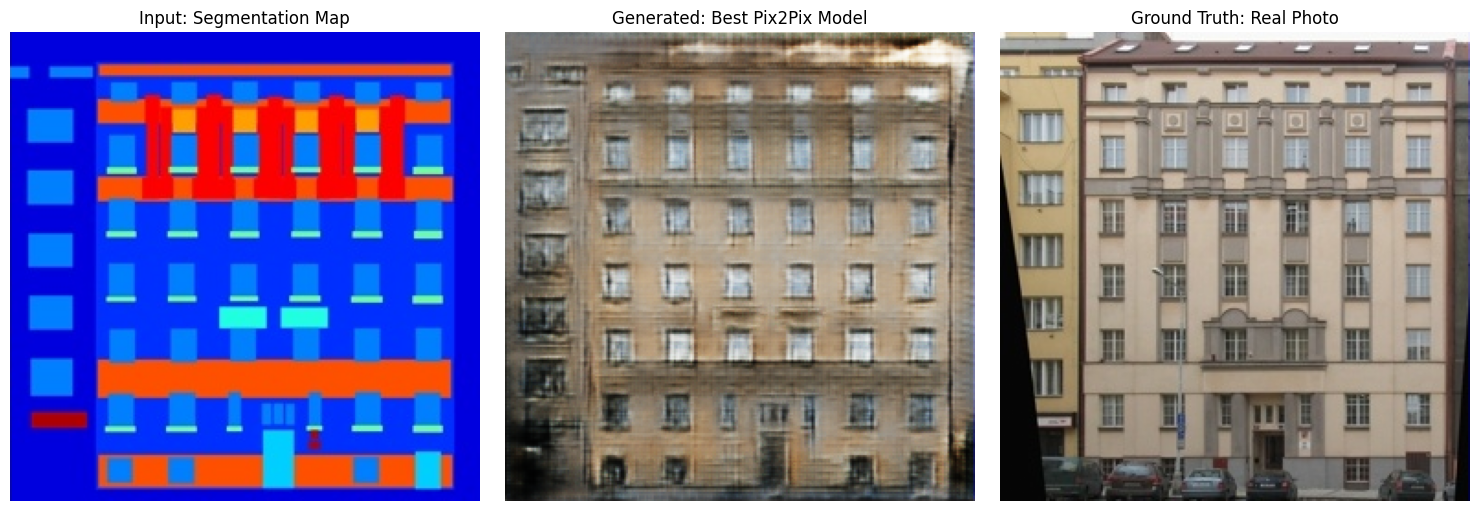

In [11]:

import torch
import matplotlib.pyplot as plt

# Load best generator
generator.load_state_dict(
    torch.load(
        "checkpoints/best_generator.pth",
        map_location=device,
        weights_only=True
    )
)

generator.eval()

# Use the same test image as before
test_input, test_target = test_dataset[0]
test_input = test_input.unsqueeze(0).to(device)

with torch.no_grad():
    generated_image = generator(test_input)

def show_image(tensor):
    return ((tensor.clamp(-1, 1) + 1) / 2).cpu()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    show_image(test_input[0]),
    show_image(generated_image[0]),
    show_image(test_target)
]

titles = [
    "Input: Segmentation Map",
    "Generated: Best Pix2Pix Model",
    "Ground Truth: Real Photo"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [12]:

import torch
from tqdm.auto import tqdm
from torchvision.utils import save_image

# Restore the latest checkpoint (epoch 10)
checkpoint = torch.load(
    "checkpoints/latest_checkpoint.pth",
    map_location=device,
    weights_only=False
)

generator.load_state_dict(checkpoint["generator"])
discriminator.load_state_dict(checkpoint["discriminator"])

optimizer_G.load_state_dict(checkpoint["optimizer_G"])
optimizer_D.load_state_dict(checkpoint["optimizer_D"])

start_epoch = checkpoint["epoch"] + 1
best_val_l1 = checkpoint["best_val_l1"]

END_EPOCH = 30

print(f"Resuming from epoch {start_epoch}...")
print(f"Best validation L1 so far: {best_val_l1:.4f}")

for epoch in range(start_epoch, END_EPOCH + 1):

    generator.train()
    discriminator.train()

    total_G_loss = 0.0
    total_D_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{END_EPOCH}"
    )

    for real_input, real_target in progress_bar:

        real_input = real_input.to(device)
        real_target = real_target.to(device)

        # Train Discriminator
        optimizer_D.zero_grad()

        fake_target = generator(real_input)

        real_prediction = discriminator(
            real_input, real_target
        )

        fake_prediction = discriminator(
            real_input, fake_target.detach()
        )

        loss_D_real = adversarial_loss(
            real_prediction,
            torch.ones_like(real_prediction)
        )

        loss_D_fake = adversarial_loss(
            fake_prediction,
            torch.zeros_like(fake_prediction)
        )

        loss_D = (loss_D_real + loss_D_fake) * 0.5

        loss_D.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()

        fake_prediction = discriminator(
            real_input, fake_target
        )

        loss_G_GAN = adversarial_loss(
            fake_prediction,
            torch.ones_like(fake_prediction)
        )

        loss_G_L1 = pixel_loss(fake_target, real_target)

        loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1

        loss_G.backward()
        optimizer_G.step()

        total_G_loss += loss_G.item()
        total_D_loss += loss_D.item()

        progress_bar.set_postfix({
            "G": f"{loss_G.item():.3f}",
            "D": f"{loss_D.item():.3f}"
        })

    avg_G_loss = total_G_loss / len(train_loader)
    avg_D_loss = total_D_loss / len(train_loader)

    # Validation
    generator.eval()
    val_l1_total = 0.0

    with torch.no_grad():
        for val_input, val_target in val_loader:
            val_input = val_input.to(device)
            val_target = val_target.to(device)

            generated = generator(val_input)
            val_l1_total += pixel_loss(
                generated, val_target
            ).item()

    avg_val_l1 = val_l1_total / len(val_loader)

    print(
        f"\nEpoch {epoch} | "
        f"G Loss: {avg_G_loss:.4f} | "
        f"D Loss: {avg_D_loss:.4f} | "
        f"Validation L1: {avg_val_l1:.4f}"
    )

    # Save latest checkpoint
    torch.save({
        "epoch": epoch,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "best_val_l1": min(best_val_l1, avg_val_l1)
    }, "checkpoints/latest_checkpoint.pth")

    # Save best generator
    if avg_val_l1 < best_val_l1:
        best_val_l1 = avg_val_l1

        torch.save(
            generator.state_dict(),
            "checkpoints/best_generator.pth"
        )

        print("New best generator saved!")

    # Save generated samples
    if epoch % 5 == 0:
        sample_input, sample_target = val_dataset[0]
        sample_input = sample_input.unsqueeze(0).to(device)

        with torch.no_grad():
            generated_sample = generator(sample_input)

        save_image(
            (generated_sample.cpu() + 1) / 2,
            f"generated_samples/generated_epoch_{epoch}.png"
        )

        print("Generated sample saved!")

print("\nTraining stage completed!")
print("Latest epoch:", END_EPOCH)
print("Best validation L1:", best_val_l1)


Resuming from epoch 21...
Best validation L1 so far: 0.3658


Epoch 21/30:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 21 | G Loss: 26.6546 | D Loss: 0.3841 | Validation L1: 0.3665


Epoch 22/30:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 22 | G Loss: 25.9744 | D Loss: 0.3863 | Validation L1: 0.3743


Epoch 23/30:   0%|          | 0/400 [00:00<?, ?it/s]

... (12 outputs left out)

Epoch 29/30:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 29 | G Loss: 22.7186 | D Loss: 0.4079 | Validation L1: 0.3641


Epoch 30/30:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 30 | G Loss: 22.3866 | D Loss: 0.3866 | Validation L1: 0.3601
Generated sample saved!

Training stage completed!
Latest epoch: 30
Best validation L1: 0.3598755159974098


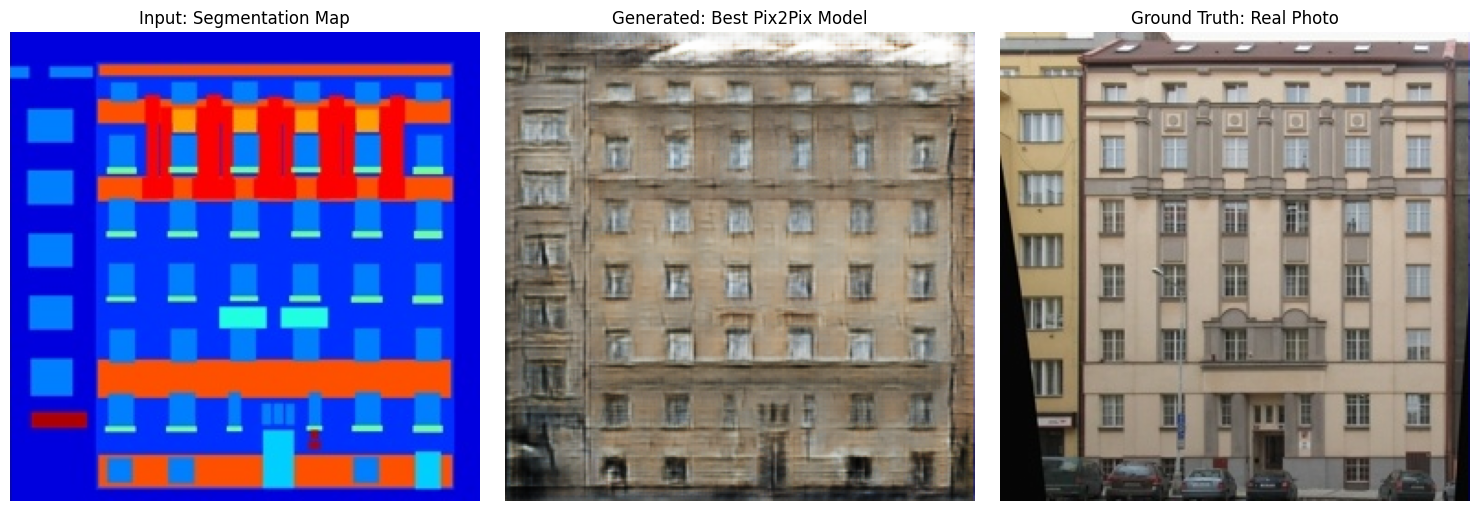

In [13]:

import torch
import matplotlib.pyplot as plt

# Load best generator
generator.load_state_dict(
    torch.load(
        "checkpoints/best_generator.pth",
        map_location=device,
        weights_only=True
    )
)

generator.eval()

# Use the same test image as before
test_input, test_target = test_dataset[0]
test_input = test_input.unsqueeze(0).to(device)

with torch.no_grad():
    generated_image = generator(test_input)

def show_image(tensor):
    return ((tensor.clamp(-1, 1) + 1) / 2).cpu()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    show_image(test_input[0]),
    show_image(generated_image[0]),
    show_image(test_target)
]

titles = [
    "Input: Segmentation Map",
    "Generated: Best Pix2Pix Model",
    "Ground Truth: Real Photo"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [14]:

import torch
from tqdm.auto import tqdm
from torchvision.utils import save_image

# Restore the latest checkpoint (epoch 10)
checkpoint = torch.load(
    "checkpoints/latest_checkpoint.pth",
    map_location=device,
    weights_only=False
)

generator.load_state_dict(checkpoint["generator"])
discriminator.load_state_dict(checkpoint["discriminator"])

optimizer_G.load_state_dict(checkpoint["optimizer_G"])
optimizer_D.load_state_dict(checkpoint["optimizer_D"])

start_epoch = checkpoint["epoch"] + 1
best_val_l1 = checkpoint["best_val_l1"]

END_EPOCH = 40

print(f"Resuming from epoch {start_epoch}...")
print(f"Best validation L1 so far: {best_val_l1:.4f}")

for epoch in range(start_epoch, END_EPOCH + 1):

    generator.train()
    discriminator.train()

    total_G_loss = 0.0
    total_D_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{END_EPOCH}"
    )

    for real_input, real_target in progress_bar:

        real_input = real_input.to(device)
        real_target = real_target.to(device)

        # Train Discriminator
        optimizer_D.zero_grad()

        fake_target = generator(real_input)

        real_prediction = discriminator(
            real_input, real_target
        )

        fake_prediction = discriminator(
            real_input, fake_target.detach()
        )

        loss_D_real = adversarial_loss(
            real_prediction,
            torch.ones_like(real_prediction)
        )

        loss_D_fake = adversarial_loss(
            fake_prediction,
            torch.zeros_like(fake_prediction)
        )

        loss_D = (loss_D_real + loss_D_fake) * 0.5

        loss_D.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()

        fake_prediction = discriminator(
            real_input, fake_target
        )

        loss_G_GAN = adversarial_loss(
            fake_prediction,
            torch.ones_like(fake_prediction)
        )

        loss_G_L1 = pixel_loss(fake_target, real_target)

        loss_G = loss_G_GAN + LAMBDA_L1 * loss_G_L1

        loss_G.backward()
        optimizer_G.step()

        total_G_loss += loss_G.item()
        total_D_loss += loss_D.item()

        progress_bar.set_postfix({
            "G": f"{loss_G.item():.3f}",
            "D": f"{loss_D.item():.3f}"
        })

    avg_G_loss = total_G_loss / len(train_loader)
    avg_D_loss = total_D_loss / len(train_loader)

    # Validation
    generator.eval()
    val_l1_total = 0.0

    with torch.no_grad():
        for val_input, val_target in val_loader:
            val_input = val_input.to(device)
            val_target = val_target.to(device)

            generated = generator(val_input)
            val_l1_total += pixel_loss(
                generated, val_target
            ).item()

    avg_val_l1 = val_l1_total / len(val_loader)

    print(
        f"\nEpoch {epoch} | "
        f"G Loss: {avg_G_loss:.4f} | "
        f"D Loss: {avg_D_loss:.4f} | "
        f"Validation L1: {avg_val_l1:.4f}"
    )

    # Save latest checkpoint
    torch.save({
        "epoch": epoch,
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "best_val_l1": min(best_val_l1, avg_val_l1)
    }, "checkpoints/latest_checkpoint.pth")

    # Save best generator
    if avg_val_l1 < best_val_l1:
        best_val_l1 = avg_val_l1

        torch.save(
            generator.state_dict(),
            "checkpoints/best_generator.pth"
        )

        print("New best generator saved!")

    # Save generated samples
    if epoch % 5 == 0:
        sample_input, sample_target = val_dataset[0]
        sample_input = sample_input.unsqueeze(0).to(device)

        with torch.no_grad():
            generated_sample = generator(sample_input)

        save_image(
            (generated_sample.cpu() + 1) / 2,
            f"generated_samples/generated_epoch_{epoch}.png"
        )

        print("Generated sample saved!")

print("\nTraining stage completed!")
print("Latest epoch:", END_EPOCH)
print("Best validation L1:", best_val_l1)


Resuming from epoch 31...
Best validation L1 so far: 0.3599


Epoch 31/40:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 31 | G Loss: 22.0647 | D Loss: 0.3986 | Validation L1: 0.3573
New best generator saved!


Epoch 32/40:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 32 | G Loss: 21.7843 | D Loss: 0.3874 | Validation L1: 0.3802


Epoch 33/40:   0%|          | 0/400 [00:00<?, ?it/s]

... (14 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7993fef6cd60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7993fef6cd60>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 39 | G Loss: 19.6644 | D Loss: 0.3918 | Validation L1: 0.3605


Epoch 40/40:   0%|          | 0/400 [00:00<?, ?it/s]


Epoch 40 | G Loss: 19.4338 | D Loss: 0.4023 | Validation L1: 0.3682
Generated sample saved!

Training stage completed!
Latest epoch: 40
Best validation L1: 0.35732238724827764


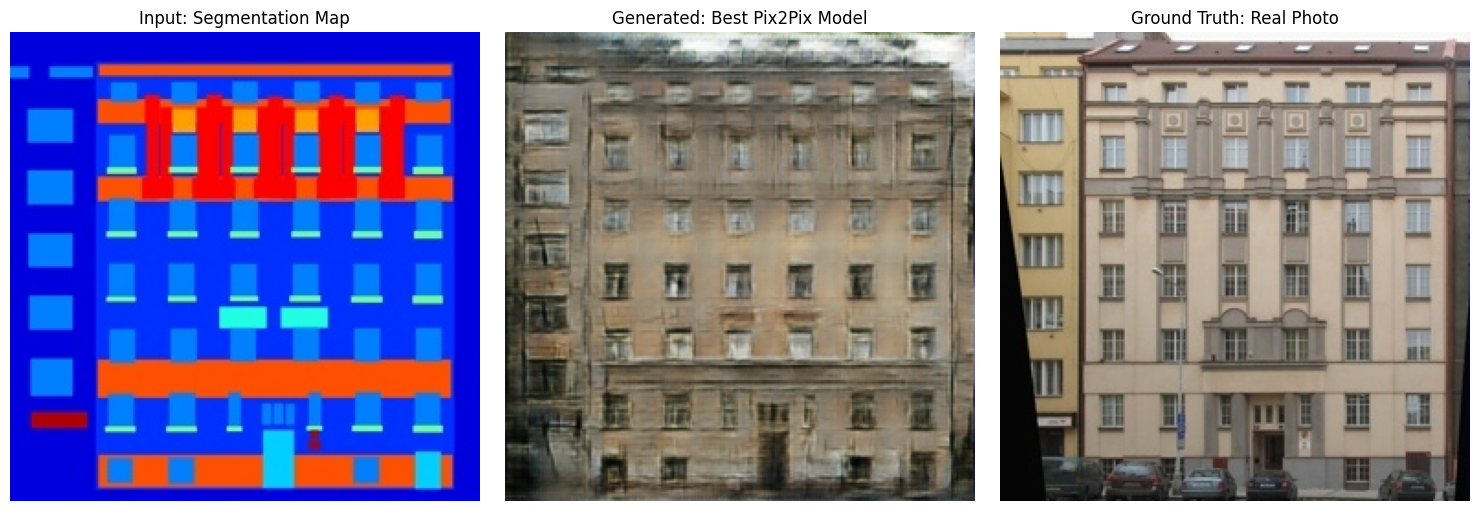

In [15]:

import torch
import matplotlib.pyplot as plt

# Load best generator
generator.load_state_dict(
    torch.load(
        "checkpoints/best_generator.pth",
        map_location=device,
        weights_only=True
    )
)

generator.eval()

# Use the same test image as before
test_input, test_target = test_dataset[0]
test_input = test_input.unsqueeze(0).to(device)

with torch.no_grad():
    generated_image = generator(test_input)

def show_image(tensor):
    return ((tensor.clamp(-1, 1) + 1) / 2).cpu()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    show_image(test_input[0]),
    show_image(generated_image[0]),
    show_image(test_target)
]

titles = [
    "Input: Segmentation Map",
    "Generated: Best Pix2Pix Model",
    "Ground Truth: Real Photo"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:

import torch
import numpy as np
from tqdm.auto import tqdm

# Load best generator
generator.load_state_dict(
    torch.load(
        "checkpoints/best_generator.pth",
        map_location=device,
        weights_only=True
    )
)

generator.eval()

total_l1 = 0.0
total_mse = 0.0
total_psnr = 0.0

with torch.no_grad():

    for test_input, test_target in tqdm(
        test_loader,
        desc="Testing Pix2Pix"
    ):

        test_input = test_input.to(device)
        test_target = test_target.to(device)

        generated = generator(test_input)

        # L1 error in normalized image space
        l1 = torch.mean(
            torch.abs(generated - test_target)
        ).item()

        # Convert images to [0, 1] for image metrics
        generated_01 = (generated + 1) / 2
        target_01 = (test_target + 1) / 2

        mse = torch.mean(
            (generated_01 - target_01) ** 2
        ).item()

        psnr = (
            float("inf") if mse == 0
            else 10 * np.log10(1.0 / mse)
        )

        total_l1 += l1
        total_mse += mse
        total_psnr += psnr

num_images = len(test_loader)

print("\n" + "=" * 45)
print("       PIX2PIX TEST EVALUATION")
print("=" * 45)

print("Test images:", num_images)
print("Average L1:", round(total_l1 / num_images, 4))
print("Average MSE:", round(total_mse / num_images, 4))
print("Average PSNR:", round(total_psnr / num_images, 2), "dB")


Testing Pix2Pix:   0%|          | 0/106 [00:00<?, ?it/s]


       PIX2PIX TEST EVALUATION
Test images: 106
Average L1: 0.3664
Average MSE: 0.057
Average PSNR: 12.66 dB


In [17]:

import os
import json
import shutil
import zipfile
import torch

# Create final project folders
os.makedirs("Pix2Pix_Project/models", exist_ok=True)
os.makedirs("Pix2Pix_Project/results", exist_ok=True)

# Save best generator
shutil.copy(
    "checkpoints/best_generator.pth",
    "Pix2Pix_Project/models/best_generator.pth"
)

# Save latest training checkpoint
shutil.copy(
    "checkpoints/latest_checkpoint.pth",
    "Pix2Pix_Project/models/latest_checkpoint.pth"
)

# Evaluation results
results = {
    "project": "Pix2Pix Image-to-Image Translation",
    "dataset": "Facades",
    "training_images": 400,
    "validation_images": 100,
    "test_images": 106,
    "epochs_completed": 40,
    "best_validation_l1": 0.35732238724827764,
    "test_l1": 0.3664,
    "test_mse": 0.057,
    "test_psnr_db": 12.66,
    "image_size": "256x256",
    "batch_size": 1,
    "learning_rate": 0.0002,
    "optimizer": "Adam",
    "architecture": "U-Net Generator + PatchGAN Discriminator"
}

with open(
    "Pix2Pix_Project/results/evaluation_results.json",
    "w"
) as file:
    json.dump(results, file, indent=4)

# Save a sample comparison
from torchvision.utils import save_image

generator.eval()

sample_input, sample_target = test_dataset[0]
sample_input = sample_input.unsqueeze(0).to(device)

with torch.no_grad():
    generated = generator(sample_input)

comparison = torch.cat([
    sample_input.cpu(),
    generated.cpu(),
    sample_target.unsqueeze(0)
], dim=0)

save_image(
    (comparison + 1) / 2,
    "Pix2Pix_Project/results/sample_comparison.png",
    nrow=3
)

# Create ZIP archive
with zipfile.ZipFile(
    "Pix2Pix_Project.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, files in os.walk("Pix2Pix_Project"):
        for filename in files:
            path = os.path.join(root, filename)
            archive.write(path, path)

print("Final artifacts saved successfully!")
print("Project ZIP: Pix2Pix_Project.zip")
print("Model, evaluation report and sample image saved.")


Final artifacts saved successfully!
Project ZIP: Pix2Pix_Project.zip
Model, evaluation report and sample image saved.


In [18]:
from google.colab import files

files.download("Pix2Pix_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>